In [7]:
import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr, wasserstein_distance

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
TRAIN = ("2023-01-01", "2024-12-31")

found = glob.glob("/Users/ashwanishah/Desktop/AQI/**/delhi_Y.csv", recursive=True)
print("R K Puram daily file found:", found)
DELHI_Y = found[0]

delhi = pd.read_csv(DELHI_Y, index_col=0, parse_dates=True).sort_index().loc[TRAIN[0]:TRAIN[1]]
print(delhi.shape, delhi.index.min(), "to", delhi.index.max(), list(delhi.columns))

R K Puram daily file found: ['/Users/ashwanishah/Desktop/AQI/MODEL/FINAL-MODEL-WORKING/delhi_saved/delhi_Y.csv']
(731, 7) 2023-01-01 00:00:00 to 2024-12-31 00:00:00 ['PM2.5', 'PM10', 'NO2', 'SO2', 'NH3', 'CO', 'OZONE']


In [6]:
import sys
sys.path.insert(0, "/Users/ashwanishah/Desktop/AQI/MODEL/Utility_fun")
import aqi_utils as U
U.leak_tests_pooled(SUMMARY_DIR)

Pooled (8 stations): errors n=111 | boundary Mann–Whitney p = 3.60e-16


np.float64(3.6011491277417004e-16)

In [11]:
# ===== Summary – Step 1: similarity vs distance (complete cell) =====
import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr, wasserstein_distance

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
TRAIN = ("2023-01-01", "2024-12-31")                      # similarity from training years only

# ---------- 0. checks before the analysis ----------
DELHI_Y = glob.glob("/Users/ashwanishah/Desktop/AQI/**/delhi_Y.csv", recursive=True)[0]
delhi = pd.read_csv(DELHI_Y, index_col=0, parse_dates=True).sort_index().loc[TRAIN[0]:TRAIN[1]]

stations = [os.path.basename(f)[len("summary_"):-4] for f in sorted(glob.glob(f"{SUMMARY_DIR}/summary_*.csv"))]
print(f"Stations found: {len(stations)} -> {stations}")
for st in stations:
    for kind in ["daily", "transfer"]:
        if not os.path.exists(f"{SUMMARY_DIR}/{kind}_{st}.csv"):
            print(f"  MISSING: {kind}_{st}.csv  (rerun Part H in the {st} notebook)")
if not any("eng" in s.lower() for s in stations):
    print("  WARNING: Bengaluru not found – rerun Part H in the Bengaluru notebook")

check = pd.concat([pd.read_csv(f"{SUMMARY_DIR}/summary_{st}.csv") for st in stations])
print("\nCheck these values:")
print(check[["station", "ring", "distance_km", "leaky_acc", "honest_acc"]].to_string(index=False))
bad = check[(check.station != "Delhi_ITO") & ((check.distance_km < 50) | (check.leaky_acc == 0.95))]
if len(bad):
    print("\n  WARNING – probably still old ITO values, rerun Part H for:", list(bad.station))

# ---------- 1. similarity table ----------
rows = []
for st in stations:
    s = pd.read_csv(f"{SUMMARY_DIR}/summary_{st}.csv").iloc[0]
    daily = pd.read_csv(f"{SUMMARY_DIR}/daily_{st}.csv", index_col=0, parse_dates=True).sort_index().loc[TRAIN[0]:TRAIN[1]]
    tr = pd.read_csv(f"{SUMMARY_DIR}/transfer_{st}.csv").set_index("setup")
    zero = tr.loc[[i for i in tr.index if str(i).startswith("Zero")][0]]
    row = {"station": st, "ring": s["ring"], "distance_km": s["distance_km"]}
    for p in ["PM2.5", "PM10"]:
        a, b = daily[p].dropna(), delhi[p].dropna()
        row[f"{p}_mean"]       = round(a.mean(), 1)
        row[f"{p}_level_diff"] = round(abs(np.log(a.mean() / b.mean())), 3)
        row[f"{p}_dist_diff"]  = round(wasserstein_distance(a, b), 1)
        row[f"{p}_zero_skill"] = round(zero[f"{p}_skill"], 3)
    rows.append(row)

sim = pd.DataFrame(rows).sort_values("distance_km")
print(f"\nR K Puram means (2023–24): PM2.5 {delhi['PM2.5'].mean():.1f}, PM10 {delhi['PM10'].mean():.1f}\n")
print(sim.to_string(index=False))
sim.to_csv(f"{SUMMARY_DIR}/similarity_table.csv", index=False)

# ---------- 2. which predicts zero-shot skill better? ----------
res = []
for p in ["PM2.5", "PM10"]:
    for name, col in [("Distance (km)", "distance_km"),
                      ("Level difference", f"{p}_level_diff"),
                      ("Distribution distance", f"{p}_dist_diff")]:
        rho, pv = spearmanr(sim[col], sim[f"{p}_zero_skill"])
        res.append({"pollutant": p, "predictor": name, "spearman_rho": round(rho, 2), "p_value": round(pv, 3)})
res = pd.DataFrame(res)
print("\nCorrelation with zero-shot skill (negative = more different -> worse transfer):")
print(res.to_string(index=False))
res.to_csv(f"{SUMMARY_DIR}/similarity_vs_distance.csv", index=False)

# ---------- 3. figure ----------
RING_COL = {"Ring 0": "#2ca02c", "Ring 1": "#ff7f0e", "Ring 2": "#1f77b4"}
def ring_colour(r): return next((c for k, c in RING_COL.items() if str(r).startswith(k)), "grey")

fig, axes = plt.subplots(2, 2, figsize=(13, 9),dpi=800)
for i, p in enumerate(["PM2.5", "PM10"]):
    for j, (col, lab, pred) in enumerate([("distance_km", "Distance from R K Puram (km)", "Distance (km)"),
                                          (f"{p}_level_diff", f"{p} level difference from Delhi  |log(mean ratio)|", "Level difference")]):
        ax = axes[i, j]
        ax.scatter(sim[col], sim[f"{p}_zero_skill"], s=80, c=[ring_colour(r) for r in sim.ring], zorder=3)
        for _, r in sim.iterrows():
            ax.annotate(r.station, (r[col], r[f"{p}_zero_skill"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
        rr = res[(res.pollutant == p) & (res.predictor == pred)].iloc[0]
        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlabel(lab); ax.set_ylabel(f"Zero-shot {p} skill")
        ax.set_title(f"{p}: Spearman ρ = {rr.spearman_rho:+.2f} (p = {rr.p_value:.3f})", fontsize=10)
        ax.grid(alpha=0.3)
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in RING_COL.items()], fontsize=8)
plt.suptitle("What predicts transfer of the Delhi model: distance or pollution-level similarity?")
plt.tight_layout(); plt.savefig(f"{SUMMARY_DIR}/similarity_vs_distance.png", dpi=800); plt.show()

Stations found: 7 -> ['Bengluru_SILK', 'Dehradun', 'Delhi_ITO', 'Guwahati', 'Punjab_Ludhiana', 'Rajesthan_jodhpur', 'bhubaneswar_PATIA']

Check these values:
          station                ring  distance_km  leaky_acc  honest_acc
    Bengluru_SILK  Ring 2 (> 1000 km)       1740.4      0.946       0.580
         Dehradun Ring 1 (150–600 km)        206.9      0.973       0.765
        Delhi_ITO    Ring 0 (< 50 km)          9.0      0.950       0.695
         Guwahati  Ring 2 (> 1000 km)       1464.2      0.926       0.684
  Punjab_Ludhiana Ring 1 (150–600 km)        290.1      0.977       0.775
Rajesthan_jodhpur Ring 1 (150–600 km)        477.8      0.970       0.701
bhubaneswar_PATIA  Ring 2 (> 1000 km)       1263.2      0.942       0.651

R K Puram means (2023–24): PM2.5 118.4, PM10 211.5

          station                ring  distance_km  PM2.5_mean  PM2.5_level_diff  PM2.5_dist_diff  PM2.5_zero_skill  PM10_mean  PM10_level_diff  PM10_dist_diff  PM10_zero_skill
        Delhi_ITO   

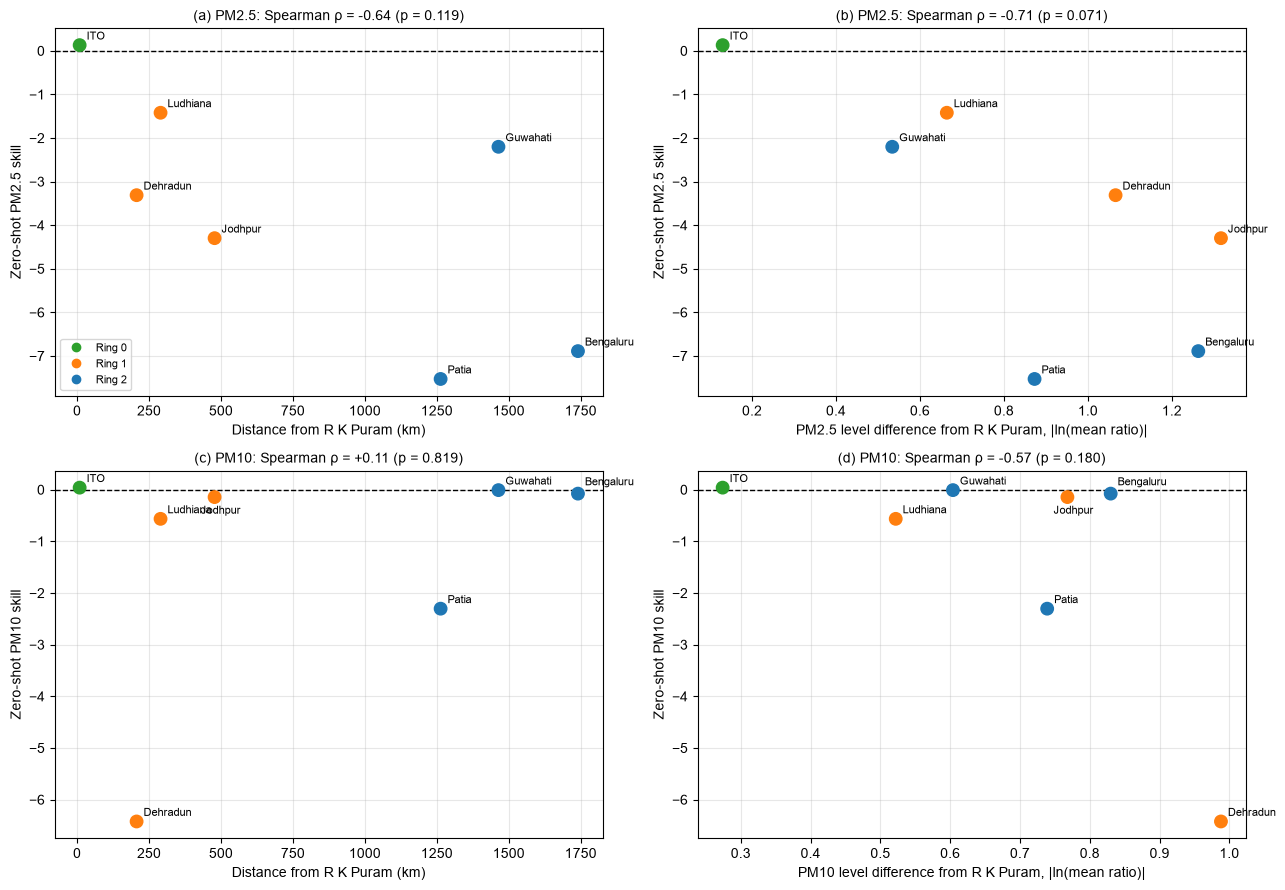

In [13]:
# ---------- 3. figure ----------
RING_COL = {"Ring 0": "#2ca02c", "Ring 1": "#ff7f0e", "Ring 2": "#1f77b4"}
def ring_colour(r): return next((c for k, c in RING_COL.items() if str(r).startswith(k)), "grey")

NAME = {"Delhi_ITO": "ITO", "Punjab_Ludhiana": "Ludhiana", "Dehradun": "Dehradun",
        "Rajesthan_jodhpur": "Jodhpur", "bhubaneswar_PATIA": "Patia",
        "Guwahati": "Guwahati", "Bengluru_SILK": "Bengaluru"}
OFFSET = {("PM10", "Rajesthan_jodhpur"): (-10, -12), ("PM10", "Bengluru_SILK"): (5, 6)}   # avoid overlaps
plt.rcParams.update({"font.family": "Arial", "svg.fonttype": "none"})

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for i, p in enumerate(["PM2.5", "PM10"]):
    for j, (col, lab, pred) in enumerate([("distance_km", "Distance from R K Puram (km)", "Distance (km)"),
                                          (f"{p}_level_diff", f"{p} level difference from R K Puram, |ln(mean ratio)|", "Level difference")]):
        ax = axes[i, j]
        ax.scatter(sim[col], sim[f"{p}_zero_skill"], s=80, c=[ring_colour(r) for r in sim.ring], zorder=3)
        for _, r in sim.iterrows():
            ax.annotate(NAME[r.station], (r[col], r[f"{p}_zero_skill"]),
                        xytext=OFFSET.get((p, r.station), (5, 4)), textcoords="offset points", fontsize=8)
        rr = res[(res.pollutant == p) & (res.predictor == pred)].iloc[0]
        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlabel(lab); ax.set_ylabel(f"Zero-shot {p} skill")
        ax.set_title(f"({'abcd'[2 * i + j]}) {p}: Spearman ρ = {rr.spearman_rho:+.2f} (p = {rr.p_value:.3f})", fontsize=10)
        ax.grid(alpha=0.3)
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in RING_COL.items()], fontsize=8)
plt.tight_layout()
plt.savefig(f"{SUMMARY_DIR}/Fig6_similarity_vs_distance.svg")
plt.savefig(f"{SUMMARY_DIR}/Fig6_similarity_vs_distance.png", dpi=800)
plt.show()

In [9]:
# ===== Summary – Step 2: level-free (relative) transfer =====
import sys, os, glob
import numpy as np, pandas as pd
sys.path.insert(0, "/Users/ashwanishah/Desktop/AQI/MODEL/Utility_fun")
import aqi_utils as U
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
DSAVE = os.path.dirname(glob.glob("/Users/ashwanishah/Desktop/AQI/**/delhi_Y.csv", recursive=True)[0])
Xd = pd.read_csv(f"{DSAVE}/delhi_X.csv", index_col=0, parse_dates=True).sort_index()
Yd = pd.read_csv(f"{DSAVE}/delhi_Y.csv", index_col=0, parse_dates=True).sort_index()

SEEDS = [0, 1, 2]
LOCAL = {1: "2024-12-01", 2: "2024-11-01", 3: "2024-10-01"}
W = 10

def make_relative(X, Y, pols):
    """Inputs and target relative to the station's own last-7-day mean (log scale)."""
    keep = [c for c in U.WEATHER_COLS + U.CALENDAR_COLS if c in X.columns]
    Xr = X[keep].copy()
    base = {p: np.log1p(X[f"{p}_mean7"]) for p in pols}
    for p in pols:
        for k in [1, 2, 3]:
            Xr[f"{p}_rel{k}"] = np.log1p(X[f"{p}_lag{k}"]) - base[p]
    R = pd.DataFrame({p: np.log1p(Y[p]) - base[p] for p in pols}, index=Y.index)
    return Xr, R

def rel_forecast(Xr_tr, R_tr, Xr_pred, X_pred, pols, seed):
    out = pd.DataFrame(index=Xr_pred.index, columns=pols, dtype=float)
    for p in pols:
        ok = R_tr[p].notna()
        m = Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("model", ExtraTreesRegressor(n_jobs=-1, random_state=seed))]).fit(Xr_tr[ok], R_tr.loc[ok, p])
        out[p] = np.expm1(m.predict(Xr_pred) + np.log1p(X_pred[f"{p}_mean7"]))   # back to µg/m³
    return out

def mean_scores(preds, days, Y, pers, pols):
    sc = pd.DataFrame([U.scores(p, days, Y, pers, pols) for p in preds])
    return round(sc.accuracy.mean(), 3), round(sc["PM2.5_skill"].mean(), 3)

stations = [os.path.basename(f)[len("X_"):-4] for f in sorted(glob.glob(f"{SUMMARY_DIR}/X_*.csv"))]
stations = [s for s in stations if s != "Delhi_RKPuram"                          # source, not a target
            and os.path.exists(f"{SUMMARY_DIR}/transfer_{s}.csv")]
print("Stations:", stations)

rows = []
for st in stations:
    Xt = pd.read_csv(f"{SUMMARY_DIR}/X_{st}.csv", index_col=0, parse_dates=True).sort_index()
    Yt = pd.read_csv(f"{SUMMARY_DIR}/daily_{st}.csv", index_col=0, parse_dates=True).sort_index()
    pols = [p for p in Yt.columns if p in Yd.columns and f"{p}_mean7" in Xt.columns and f"{p}_mean7" in Xd.columns]
    pers = pd.DataFrame({p: Xt[f"{p}_lag1"] for p in pols})
    test = U.in_period(Xt.index, "test")
    d_fit, t_fit = Xd.index <= "2024-12-31", Xt.index <= "2024-12-31"

    Xr_d, R_d = make_relative(Xd, Yd, pols)
    Xr_t, R_t = make_relative(Xt, Yt, pols)
    cols = [c for c in Xr_t.columns if c in Xr_d.columns]
    Xr_d, Xr_t = Xr_d[cols], Xr_t[cols]

    own  = [rel_forecast(Xr_t[t_fit], R_t[t_fit], Xr_t, Xt, pols, s) for s in SEEDS]
    zero = [rel_forecast(Xr_d[d_fit], R_d[d_fit], Xr_t, Xt, pols, s) for s in SEEDS]
    lm = (Xt.index >= LOCAL[3]) & (Xt.index <= "2024-12-31")
    few3 = [rel_forecast(pd.concat([Xr_d[d_fit]] + [Xr_t[lm]] * W), pd.concat([R_d[d_fit]] + [R_t[lm]] * W),
                         Xr_t, Xt, pols, s) for s in SEEDS]

    # normal (absolute) results from the station notebook, for comparison
    tr = pd.read_csv(f"{SUMMARY_DIR}/transfer_{st}.csv").set_index("setup")
    pick = lambda pre: tr.loc[[i for i in tr.index if str(i).startswith(pre)][0]]
    pick3 = tr.loc[[i for i in tr.index if str(i).startswith("Few") and "3" in str(i)][0]]

    r = {"station": st, "persistence_acc": U.scores(pers, test, Yt, pers, pols)["accuracy"]}
    r["zero_acc_abs"], r["zero_skill_abs"] = pick("Zero")["accuracy"], pick("Zero")["PM2.5_skill"]
    r["zero_acc_rel"], r["zero_skill_rel"] = mean_scores(zero, test, Yt, pers, pols)
    r["few3_acc_abs"], r["few3_skill_abs"] = pick3["accuracy"], pick3["PM2.5_skill"]
    r["few3_acc_rel"], r["few3_skill_rel"] = mean_scores(few3, test, Yt, pers, pols)
    r["own_acc_abs"], r["own_skill_abs"]   = pick("Own")["accuracy"], pick("Own")["PM2.5_skill"]
    r["own_acc_rel"], r["own_skill_rel"]   = mean_scores(own, test, Yt, pers, pols)
    rows.append(r)
    print("done:", st)

lf = pd.DataFrame(rows)
pd.set_option("display.width", 250)
print("\nNormal (abs) vs level-free (rel) model, test 2025:")
print(lf.to_string(index=False))
lf.to_csv(f"{SUMMARY_DIR}/level_free_transfer.csv", index=False)

# ---- check at the source: does level-free hurt Delhi itself? (5 pollutants used for the AQI at Delhi) ----
pols_d = ["PM2.5", "PM10", "NO2", "SO2", "CO"]
pers_d = pd.DataFrame({p: Xd[f"{p}_lag1"] for p in pols_d})
test_d = U.in_period(Xd.index, "test")
Xr_dd, R_dd = make_relative(Xd, Yd, pols_d)
rel_d = [rel_forecast(Xr_dd[d_fit], R_dd[d_fit], Xr_dd, Xd, pols_d, s) for s in SEEDS]
abs_d = [U.forecast(Xd[d_fit], Yd[d_fit], Xd, pols_d, "ExtraTrees", {"random_state": s}) for s in SEEDS]
print("\nAt R K Puram itself (2025): persistence", U.scores(pers_d, test_d, Yd, pers_d, pols_d)["accuracy"],
      "| normal (acc, PM2.5 skill)", mean_scores(abs_d, test_d, Yd, pers_d, pols_d),
      "| level-free", mean_scores(rel_d, test_d, Yd, pers_d, pols_d))

Stations: ['Bengluru_SILK', 'Dehradun', 'Delhi_ITO', 'Guwahati', 'Punjab_Ludhiana', 'Rajesthan_jodhpur', 'bhubaneswar_PATIA']
done: Bengluru_SILK
done: Dehradun
done: Delhi_ITO
done: Guwahati
done: Punjab_Ludhiana
done: Rajesthan_jodhpur
done: bhubaneswar_PATIA

Normal (abs) vs level-free (rel) model, test 2025:
          station  persistence_acc  zero_acc_abs  zero_skill_abs  zero_acc_rel  zero_skill_rel  few3_acc_abs  few3_skill_abs  few3_acc_rel  few3_skill_rel  own_acc_abs  own_skill_abs  own_acc_rel  own_skill_rel
    Bengluru_SILK            0.702         0.626          -6.889         0.669          -0.209         0.609           0.068         0.718           0.098        0.635          0.095        0.748          0.115
         Dehradun            0.776         0.335          -3.312         0.710          -0.033         0.468          -1.967         0.714          -0.017        0.768          0.079        0.734          0.158
        Delhi_ITO            0.657         0.705     

In [10]:
# ===== Summary – Step 2b: statistical validation of the level-free model =====
from scipy import stats
from statsmodels.stats.multitest import multipletests

EQ_MARGIN = 0.05                                   # equivalence margin: ±5 accuracy points (state in paper)

def dm_test(actual, pred_a, pred_b, lag=7):
    """Diebold–Mariano on squared errors, Newey–West corrected. DM > 0 means A is better than B."""
    ok = actual.notna() & pred_a.notna() & pred_b.notna()
    d = ((actual[ok] - pred_b[ok])**2 - (actual[ok] - pred_a[ok])**2).values
    n, dc = len(d), d - d.mean()
    var = np.sum(dc * dc) / n
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * np.sum(dc[k:] * dc[:-k]) / n
    dm = d.mean() / np.sqrt(var / n)
    return dm, 2 * (1 - stats.norm.cdf(abs(dm)))

def ci_bounds(s):                                  # "[-0.012, +0.034]" -> (-0.012, 0.034)
    return tuple(map(float, s.strip("[]").split(",")))

rows = []
for st in stations:
    Xt = pd.read_csv(f"{SUMMARY_DIR}/X_{st}.csv", index_col=0, parse_dates=True).sort_index()
    Yt = pd.read_csv(f"{SUMMARY_DIR}/daily_{st}.csv", index_col=0, parse_dates=True).sort_index()
    pols = [p for p in Yt.columns if p in Yd.columns and f"{p}_mean7" in Xt.columns and f"{p}_mean7" in Xd.columns]
    pers = pd.DataFrame({p: Xt[f"{p}_lag1"] for p in pols})
    test = U.in_period(Xt.index, "test")
    d_fit = Xd.index <= "2024-12-31"

    # level-free zero-shot
    Xr_d, R_d = make_relative(Xd, Yd, pols)
    Xr_t, R_t = make_relative(Xt, Yt, pols)
    cols = [c for c in Xr_t.columns if c in Xr_d.columns]
    rel_zero = [rel_forecast(Xr_d.loc[d_fit, cols], R_d[d_fit], Xr_t[cols], Xt, pols, s) for s in SEEDS]

    # normal zero-shot (recomputed with the same seeds, for a paired comparison)
    feats = [c for c in Xt.columns if c in Xd.columns]
    abs_zero = [U.forecast(Xd.loc[d_fit, feats], Yd.loc[d_fit, pols], Xt[feats], pols, "ExtraTrees",
                           {"random_state": s}) for s in SEEDS]

    vs_pers = U.gain_ci(rel_zero, test, Yt, pers, pols)          # level-free vs persistence
    vs_abs  = U.gain_ci(rel_zero, test, Yt, abs_zero[0], pols)   # level-free vs normal zero-shot
    a = Yt.loc[test, "PM2.5"]
    dm_p, p_p = dm_test(a, rel_zero[0].loc[test, "PM2.5"], pers.loc[test, "PM2.5"])
    dm_a, p_a = dm_test(a, rel_zero[0].loc[test, "PM2.5"], abs_zero[0].loc[test, "PM2.5"])
    lo, hi = ci_bounds(vs_pers["acc_gain_95CI"])

    rows.append({"station": st, "days": vs_pers["days"],
                 # 1. vs normal zero-shot
                 "gain_vs_normal_acc": vs_abs["acc_gain"], "gain_vs_normal_acc_CI": vs_abs["acc_gain_95CI"],
                 "gain_vs_normal_F1_CI": vs_abs["F1_gain_95CI"], "DM_vs_normal": round(dm_a, 2), "p_vs_normal": p_a,
                 # 2. vs persistence
                 "gain_vs_pers_acc": vs_pers["acc_gain"], "gain_vs_pers_acc_CI": vs_pers["acc_gain_95CI"],
                 "gain_vs_pers_F1_CI": vs_pers["F1_gain_95CI"], "DM_vs_pers": round(dm_p, 2), "p_vs_pers": p_p,
                 # 3. equivalence with persistence (whole CI within ±margin)
                 "equivalent_to_pers": (lo >= -EQ_MARGIN) and (hi <= EQ_MARGIN)})
    print("done:", st)

val = pd.DataFrame(rows)
val["p_vs_normal_Holm"] = multipletests(val["p_vs_normal"], method="holm")[1]
val["p_vs_pers_Holm"]   = multipletests(val["p_vs_pers"],   method="holm")[1]
for c in ["p_vs_normal", "p_vs_pers", "p_vs_normal_Holm", "p_vs_pers_Holm"]:
    val[c] = val[c].round(4)

pd.set_option("display.width", 300)
print("\n1. Level-free vs NORMAL zero-shot (positive = level-free better):")
print(val[["station", "days", "gain_vs_normal_acc", "gain_vs_normal_acc_CI", "gain_vs_normal_F1_CI",
           "DM_vs_normal", "p_vs_normal_Holm"]].to_string(index=False))
print("\n2–3. Level-free zero-shot vs PERSISTENCE:")
print(val[["station", "gain_vs_pers_acc", "gain_vs_pers_acc_CI", "gain_vs_pers_F1_CI",
           "DM_vs_pers", "p_vs_pers_Holm", "equivalent_to_pers"]].to_string(index=False))
val.to_csv(f"{SUMMARY_DIR}/level_free_validation.csv", index=False)

# ---- at the source (R K Puram): is the level-free model's loss significant? ----
src = U.gain_ci(rel_d, test_d, Yd, abs_d[0], pols_d)
dm_s, p_s = dm_test(Yd.loc[test_d, "PM2.5"], rel_d[0].loc[test_d, "PM2.5"], abs_d[0].loc[test_d, "PM2.5"])
print(f"\nR K Puram, level-free minus normal: accuracy {src['acc_gain']:+.3f} {src['acc_gain_95CI']} | "
      f"macro-F1 {src['F1_gain']:+.3f} {src['F1_gain_95CI']} | PM2.5 DM {dm_s:+.2f} (p = {p_s:.4f}; DM < 0 = level-free worse)")

done: Bengluru_SILK
done: Dehradun
done: Delhi_ITO
done: Guwahati
done: Punjab_Ludhiana
done: Rajesthan_jodhpur
done: bhubaneswar_PATIA

1. Level-free vs NORMAL zero-shot (positive = level-free better):
          station  days  gain_vs_normal_acc gain_vs_normal_acc_CI gain_vs_normal_F1_CI  DM_vs_normal  p_vs_normal_Holm
    Bengluru_SILK   169               0.086      [-0.012, +0.187]     [+0.093, +0.383]         10.71            0.0000
         Dehradun   284               0.366      [+0.241, +0.525]     [+0.235, +0.487]          8.37            0.0000
        Delhi_ITO   327              -0.011      [-0.052, +0.027]     [-0.126, +0.129]         -0.01            0.9886
         Guwahati   194               0.290      [+0.174, +0.410]     [+0.244, +0.455]          5.14            0.0000
  Punjab_Ludhiana   355               0.186      [+0.086, +0.277]     [+0.025, +0.301]          4.61            0.0000
Rajesthan_jodhpur   331               0.155      [+0.074, +0.228]     [+0.107, +0.2

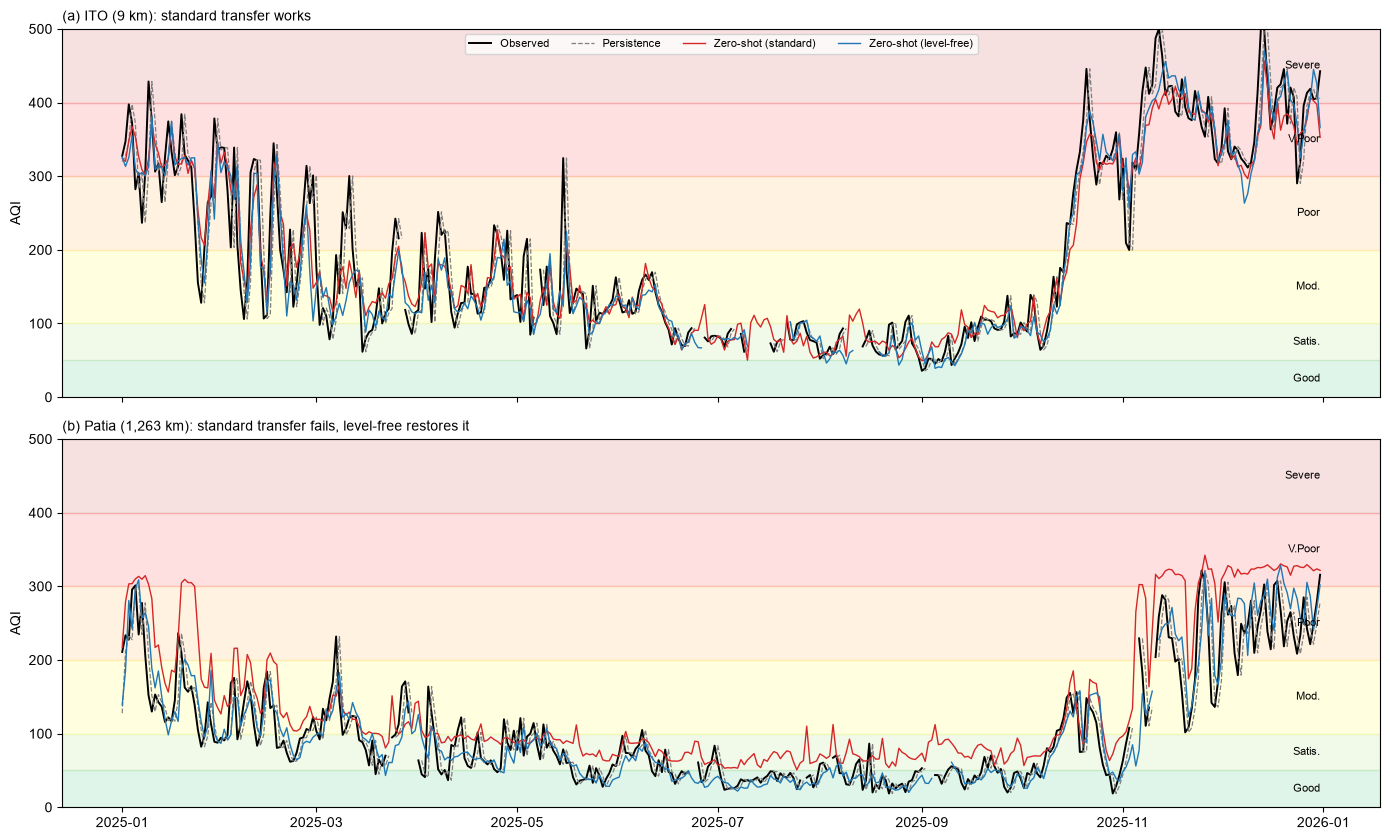

In [16]:
# ===== Fig. 7: How transfer works – best (ITO) and worst (Patia) case, AQI 2025 =====
BANDS   = [0, 50, 100, 200, 300, 400, 500]
COLOURS = ["#00b050", "#92d050", "#ffff00", "#ff9900", "#ff0000", "#c00000"]   # CPCB colours
SHORT   = ["Good", "Satis.", "Mod.", "Poor", "V.Poor", "Severe"]
CASES   = [("Delhi_ITO", "ITO (9 km): standard transfer works"),
           ("bhubaneswar_PATIA", "Patia (1,263 km): standard transfer fails, level-free restores it")]
plt.rcParams.update({"font.family": "Arial", "svg.fonttype": "none"})
d_fit = Xd.index <= "2024-12-31"

fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True)
for ax, (st, title), letter in zip(axes, CASES, "ab"):
    Xt = pd.read_csv(f"{SUMMARY_DIR}/X_{st}.csv", index_col=0, parse_dates=True).sort_index()
    Yt = pd.read_csv(f"{SUMMARY_DIR}/daily_{st}.csv", index_col=0, parse_dates=True).sort_index()
    pols = [p for p in Yt.columns if p in Yd.columns and f"{p}_mean7" in Xt.columns and f"{p}_mean7" in Xd.columns]
    pers = pd.DataFrame({p: Xt[f"{p}_lag1"] for p in pols})
    feats = [c for c in Xt.columns if c in Xd.columns]

    abs_zero = U.forecast(Xd.loc[d_fit, feats], Yd.loc[d_fit, pols], Xt[feats], pols, "ExtraTrees", {"random_state": 0})
    Xr_d, R_d = make_relative(Xd, Yd, pols); Xr_t, _ = make_relative(Xt, Yt, pols)
    cols = [c for c in Xr_t.columns if c in Xr_d.columns]
    rel_zero = rel_forecast(Xr_d.loc[d_fit, cols], R_d[d_fit], Xr_t[cols], Xt, pols, 0)

    s = lambda conc: U.compute_aqi(conc, pols).loc["2025"].asfreq("D")
    for lo, hi, c, lab in zip(BANDS[:-1], BANDS[1:], COLOURS, SHORT):
        ax.axhspan(lo, hi, color=c, alpha=0.12)
        ax.text(pd.Timestamp("2025-12-31"), (lo + hi) / 2, lab, fontsize=8, va="center", ha="right")
    ax.plot(s(Yt),       color="black",    lw=1.4,          label="Observed")
    ax.plot(s(pers),     color="grey",     lw=0.9, ls="--", label="Persistence")
    ax.plot(s(abs_zero), color="tab:red",  lw=1.0,          label="Zero-shot (standard)")
    ax.plot(s(rel_zero), color="tab:blue", lw=1.0,          label="Zero-shot (level-free)")
    ax.set_ylim(0, 500); ax.set_ylabel("AQI")
    ax.set_title(f"({letter}) {title}", fontsize=10, loc="left")
axes[0].legend(ncol=4, fontsize=8, loc="upper center")
plt.tight_layout()
plt.savefig(f"{SUMMARY_DIR}/Fig7_transfer_ITO_Patia.svg")
plt.savefig(f"{SUMMARY_DIR}/Fig7_transfer_ITO_Patia.png", dpi=800)
plt.show()

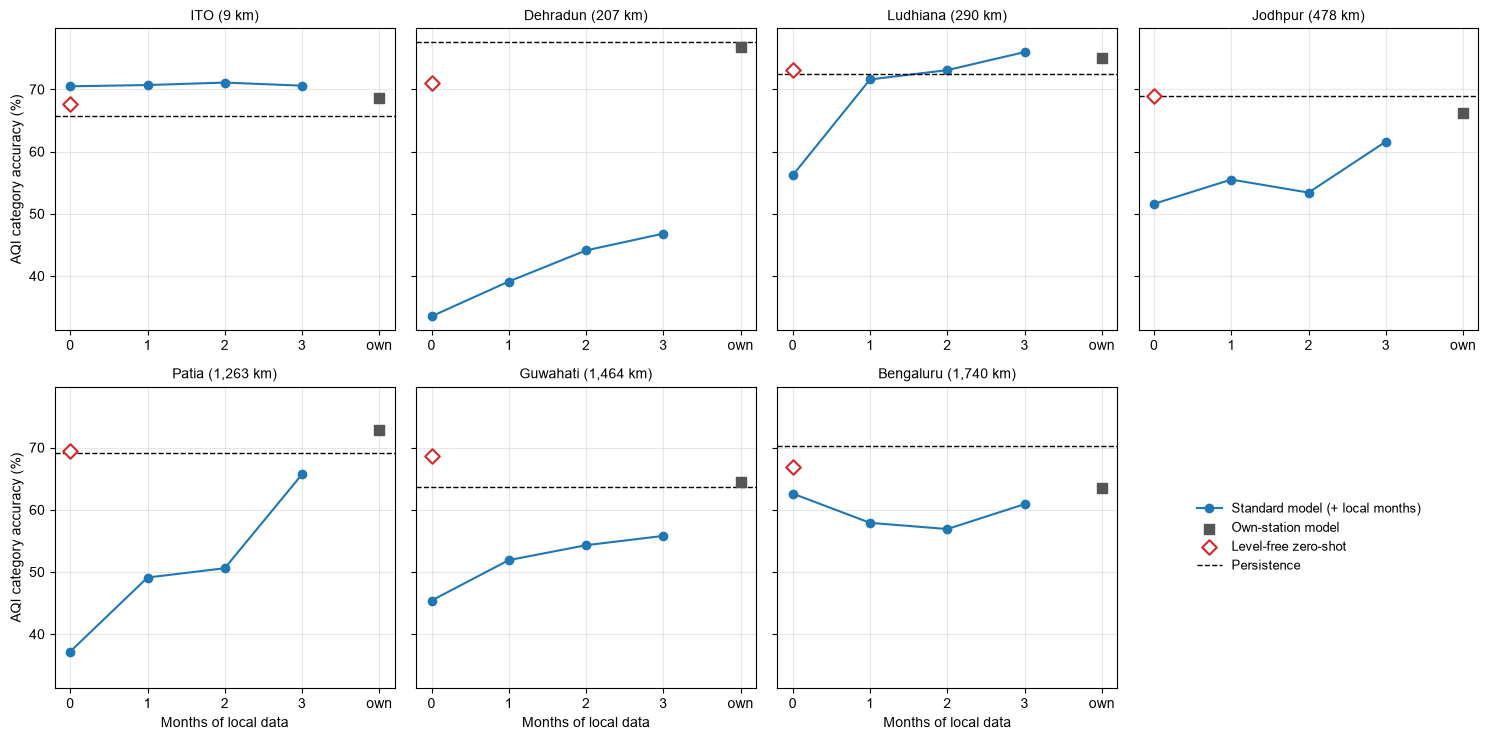

In [17]:
# ===== Fig. S7: Transfer at all seven stations – accuracy vs months of local data (test 2025) =====
NAME = {"Delhi_ITO": "ITO (9 km)", "Dehradun": "Dehradun (207 km)", "Punjab_Ludhiana": "Ludhiana (290 km)",
        "Rajesthan_jodhpur": "Jodhpur (478 km)", "bhubaneswar_PATIA": "Patia (1,263 km)",
        "Guwahati": "Guwahati (1,464 km)", "Bengluru_SILK": "Bengaluru (1,740 km)"}
ORDER = list(NAME)                                            # sorted by distance
lf = pd.read_csv(f"{SUMMARY_DIR}/level_free_transfer.csv").set_index("station")
plt.rcParams.update({"font.family": "Arial", "svg.fonttype": "none"})

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), sharey=True)
for ax, st in zip(axes.flat, ORDER):
    tr = pd.read_csv(f"{SUMMARY_DIR}/transfer_{st}.csv").set_index("setup")
    get = lambda pre, k="": tr.loc[[i for i in tr.index if str(i).startswith(pre) and k in str(i)][0], "accuracy"] * 100
    steps = [get("Zero"), get("Few", "1 month"), get("Few", "2 month"), get("Few", "3 month")]
    ax.plot([0, 1, 2, 3], steps, marker="o", color="#1f77b4", label="Standard model (+ local months)")
    ax.scatter([4], [get("Own")], marker="s", s=60, color="#555555", zorder=5, label="Own-station model")
    ax.scatter([0], [lf.loc[st, "zero_acc_rel"] * 100], marker="D", s=55, facecolor="white",
               edgecolor="#d62728", linewidth=1.5, zorder=6, label="Level-free zero-shot")
    ax.axhline(get("Persistence"), color="black", ls="--", lw=1, label="Persistence")
    ax.set_title(NAME[st], fontsize=10)
    ax.set_xticks([0, 1, 2, 3, 4]); ax.set_xticklabels(["0", "1", "2", "3", "own"])
    ax.grid(alpha=0.3)
for ax in axes[:, 0]: ax.set_ylabel("AQI category accuracy (%)")
for ax in axes[1, :3]: ax.set_xlabel("Months of local data")
axes[1, 3].axis("off")
axes[1, 3].legend(*axes[0, 0].get_legend_handles_labels(), loc="center", fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(f"{SUMMARY_DIR}/FigS7_transfer_all_stations.svg")
plt.savefig(f"{SUMMARY_DIR}/FigS7_transfer_all_stations.png", dpi=800)
plt.show()